# EXP-001 — Unified Food Classification: 4 original datasets

## 1. Project overview
30VNFoods + UEC-Food256 + VinaFood21 + Vietnamese_StreetFood_14Class.
Original archives are read-only. No Unified Detection data is loaded. Classification
images retain source labels; detection annotations yield individual crops, including
multiple crops per image. Ambiguous taxonomy matches remain separate.

Full training and test evaluation are **disabled by default**. The training cell calls
the existing trainer with every valid train sample and no batch limit.


In [1]:
from pathlib import Path
import sys, os, json
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'scripts/classification.py').is_file()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
os.environ.setdefault('TORCH_HOME', str(ROOT / '.cache/torch'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, yaml
from classification.unified import load_unified, open_sample, ArchiveReader
from classification.model import build_model
from classification.data import preprocess
from scripts import classification as trainer
CFG = yaml.safe_load((ROOT / 'configs/classification-unified-exp001.yaml').read_text())
DATA = ROOT / CFG['manifest_root']
RUN = ROOT / 'runs/exp-001-unified4'
RUN_FULL_TRAIN = False
RUN_TEST_EVALUATION = False


## 2. Python and CUDA
Select the `ai-unified` kernel backed by `D:\CondaEnvs\ai\python.exe`.

In [2]:
print('Python:', sys.executable, sys.version)
assert Path(sys.executable).resolve() == Path('D:/CondaEnvs/ai/python.exe').resolve()
print('PyTorch:', torch.__version__, 'CUDA runtime:', torch.version.cuda)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'Unavailable — CPU supported')
assert CFG['seed'] is None


Python: D:\CondaEnvs\ai\python.exe 3.11.17 | packaged by Anaconda, Inc. | (main, Oct  1 2026, 20:16:54) [MSC v.1942 64 bit (AMD64)]
PyTorch: 2.11.0+cu128 CUDA runtime: 12.8
GPU: NVIDIA GeForce RTX 5050 Laptop GPU


## 3. Four-source audit
Counts refer to original archive entries. Identical images can appear in multiple class folders; consult duplicate audit for unique content. VinaFood21 has no native validation split; UEC splits are explicitly derived. No source validation/test samples enter train.

In [3]:
report = json.loads((DATA / 'report.json').read_text(encoding='utf-8'))
display(pd.DataFrame(report['sources']).T.fillna(0))
display(pd.DataFrame(report['samples_by_source']).T.fillna(0).astype(int))
print(report['split_policy'])
print(report['near_duplicate_limit'])
display(pd.Series(report['exclusions'], name='excluded'))


,original_images,annotations,classes,original_splits,unique_decoded_images,bounding_boxes,segmentation_regions,retained_samples,annotation_files,bounding_regions
30VNFoods,25136,25136,30,"{'test': 5040, 'val': 2515, 'train': 17581}",25063,0,0,21989,0,0
UEC-Food256,31395,31645,256,{'unspecified': 31395},29482,31645,0,31261,256,0
VinaFood21,16726,16726,21,"{'test': 6682, 'train': 10044}",16628,0,0,16389,0,0
Vietnamese_StreetFood_14Class,3526,4019,14,"{'val': 1071, 'train': 1385, 'test': 1070}",3526,4002,17,2001,3526,4019


,train,val,test
30VNFoods,14553,2411,5025
UEC-Food256,24905,3221,3135
VinaFood21,9759,0,6630
Vietnamese_StreetFood_14Class,319,478,1204


Preserve original splits. VinaFood21 retains all eligible original train; no invented val. UEC has no split metadata: native image-ID SHA256 bucket 80/10/10. Conflicting groups retain only highest-priority original split test > val > train; never relocate rows.
Original images AND actual crops: 64-bit dHash radius 4 plus 16x16 RGB MAE <=8. Heuristic cannot prove absence of all transformed copies.


bbox_out_of_bounds                  2
crop_too_small_or_degenerate       10
cross_split_group_quarantine     5684
duplicate_sample                  117
conflicting_region_labels          70
cross_split_region_quarantine       3
Name: excluded, dtype: int64

## 4. Unified class mapping
Only exact labels normalized for case and separators are merged; semantic translations require review. Source IDs and canonical IDs are recorded independently.

In [4]:
root, mapping, datasets = load_unified(ROOT, CFG, ('train', 'val', 'test'))
display(pd.DataFrame(mapping['provenance']))
print('Canonical classes:', len(mapping['classes']))
print('Merged source classes:', report['merged_class_count'])
display(pd.read_csv(DATA / 'taxonomy_review.csv').head(20))


,source,source_class_id,source_name,canonical_id,evidence
0,30VNFoods,0,Banh beo,0,Exact normalized source label; punctuation/cas...
1,30VNFoods,1,Banh bot loc,1,Exact normalized source label; punctuation/cas...
2,30VNFoods,2,Banh can,2,Exact normalized source label; punctuation/cas...
3,30VNFoods,3,Banh canh,3,Exact normalized source label; punctuation/cas...
4,30VNFoods,4,Banh chung,4,Exact normalized source label; punctuation/cas...
...,...,...,...,...,...
316,Vietnamese_StreetFood_14Class,9,Broken Rice,313,Exact normalized source label; punctuation/cas...
317,Vietnamese_StreetFood_14Class,10,Fried Rice,38,Exact normalized source label; punctuation/cas...
318,Vietnamese_StreetFood_14Class,11,Beef Pho,314,Exact normalized source label; punctuation/cas...
319,Vietnamese_StreetFood_14Class,12,Spring Rolls,315,Exact normalized source label; punctuation/cas...


Canonical classes: 317
Merged source classes: 4


,left_source,left_source_class_id,left_source_name,left_canonical_id,right_source,right_source_class_id,right_source_name,right_canonical_id,status,evidence
0,30VNFoods,5,Banh cuon,5,UEC-Food256,210,Steamed rice roll,238,keep_separate_pending_review,"Source names suggest a translation, variant, o..."
1,30VNFoods,5,Banh cuon,5,Vietnamese_StreetFood_14Class,0,Steamed Rice Rolls,304,keep_separate_pending_review,"Source names suggest a translation, variant, o..."
2,30VNFoods,5,Banh cuon,5,VinaFood21,6,banh-uot,289,keep_separate_pending_review,"Source names suggest a translation, variant, o..."
3,30VNFoods,7,Banh gio,7,Vietnamese_StreetFood_14Class,1,Vietnamese pyramid rice dumpling,305,keep_separate_pending_review,"Source names suggest a translation, variant, o..."
4,30VNFoods,9,Banh mi,9,Vietnamese_StreetFood_14Class,2,Grilled Pork Banh Mi,306,keep_separate_pending_review,"Source names suggest a translation, variant, o..."
5,30VNFoods,14,Bun bo Hue,14,UEC-Food256,207,Hue beef rice vermicelli soup,235,keep_separate_pending_review,"Source names suggest a translation, variant, o..."
6,30VNFoods,14,Bun bo Hue,14,Vietnamese_StreetFood_14Class,3,Hue-style Spicy Beef Noodle Soup,307,keep_separate_pending_review,"Source names suggest a translation, variant, o..."
7,30VNFoods,18,Bun thit nuong,18,Vietnamese_StreetFood_14Class,4,Grilled Pork with Vermicelli,308,keep_separate_pending_review,"Source names suggest a translation, variant, o..."
8,30VNFoods,18,Bun thit nuong,18,Vietnamese_StreetFood_14Class,6,Grilled Pork Vermicelli,310,keep_separate_pending_review,"Source names suggest a translation, variant, o..."
9,Vietnamese_StreetFood_14Class,4,Grilled Pork with Vermicelli,308,Vietnamese_StreetFood_14Class,6,Grilled Pork Vermicelli,310,keep_separate_pending_review,"Source names suggest a translation, variant, o..."


## 5. Class distribution

After leakage quarantine, classes 307 (Hue-style Spicy Beef Noodle Soup) and 310 (Grilled Pork Vermicelli) have no retained train samples. Their output classes remain, but cannot learn positive examples. No holdout rows are moved into train. VinaFood21 has no native validation split.

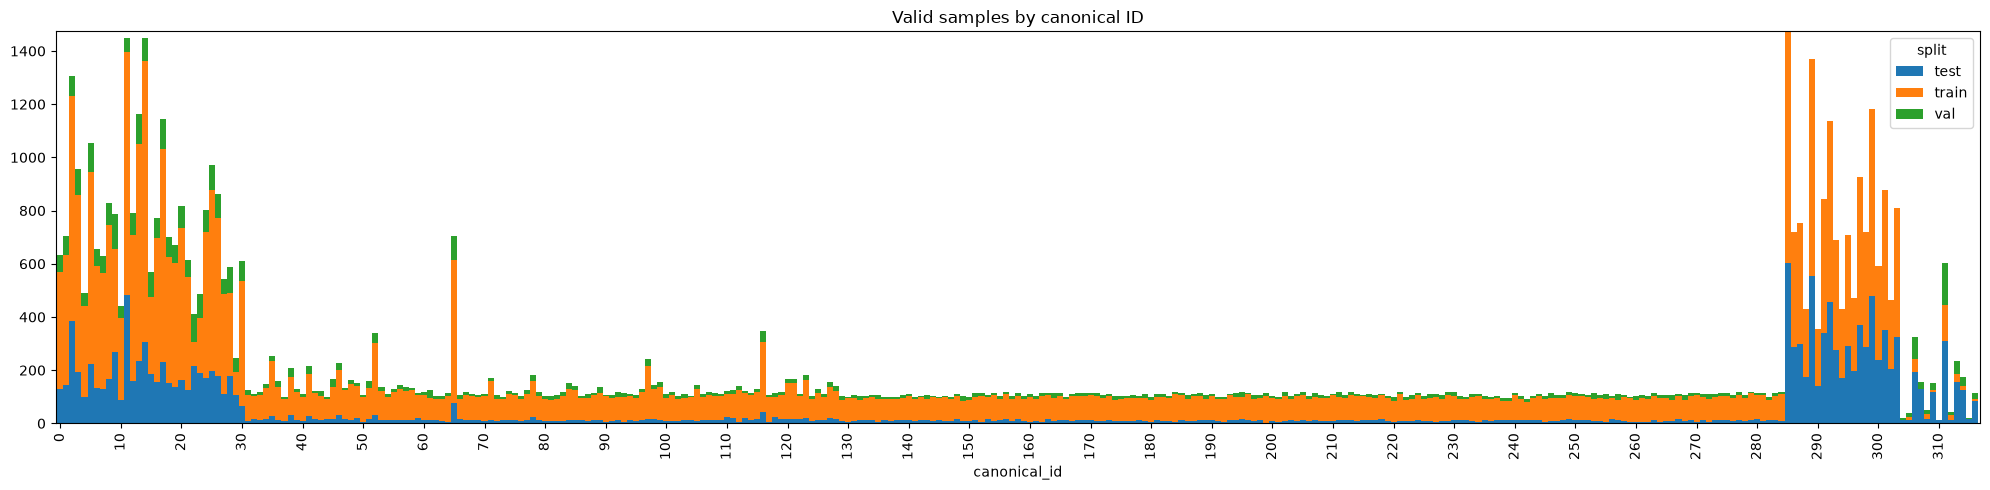

Classes without training support: [307, 310]


In [5]:
rows = pd.DataFrame([r for ds in datasets.values() for r in ds.rows])
distribution = pd.crosstab(rows.canonical_id, rows.split).reindex(range(len(mapping['classes'])), fill_value=0)
distribution.plot.bar(stacked=True, figsize=(20, 5), width=1)
plt.xticks(range(0, len(mapping['classes']), 10)); plt.title('Valid samples by canonical ID'); plt.tight_layout(); plt.show()
print('Classes without training support:', distribution.index[distribution.train.eq(0)].tolist())


## 6. Original images and detection crops
Each detection sample retains its source annotation and original image identity.

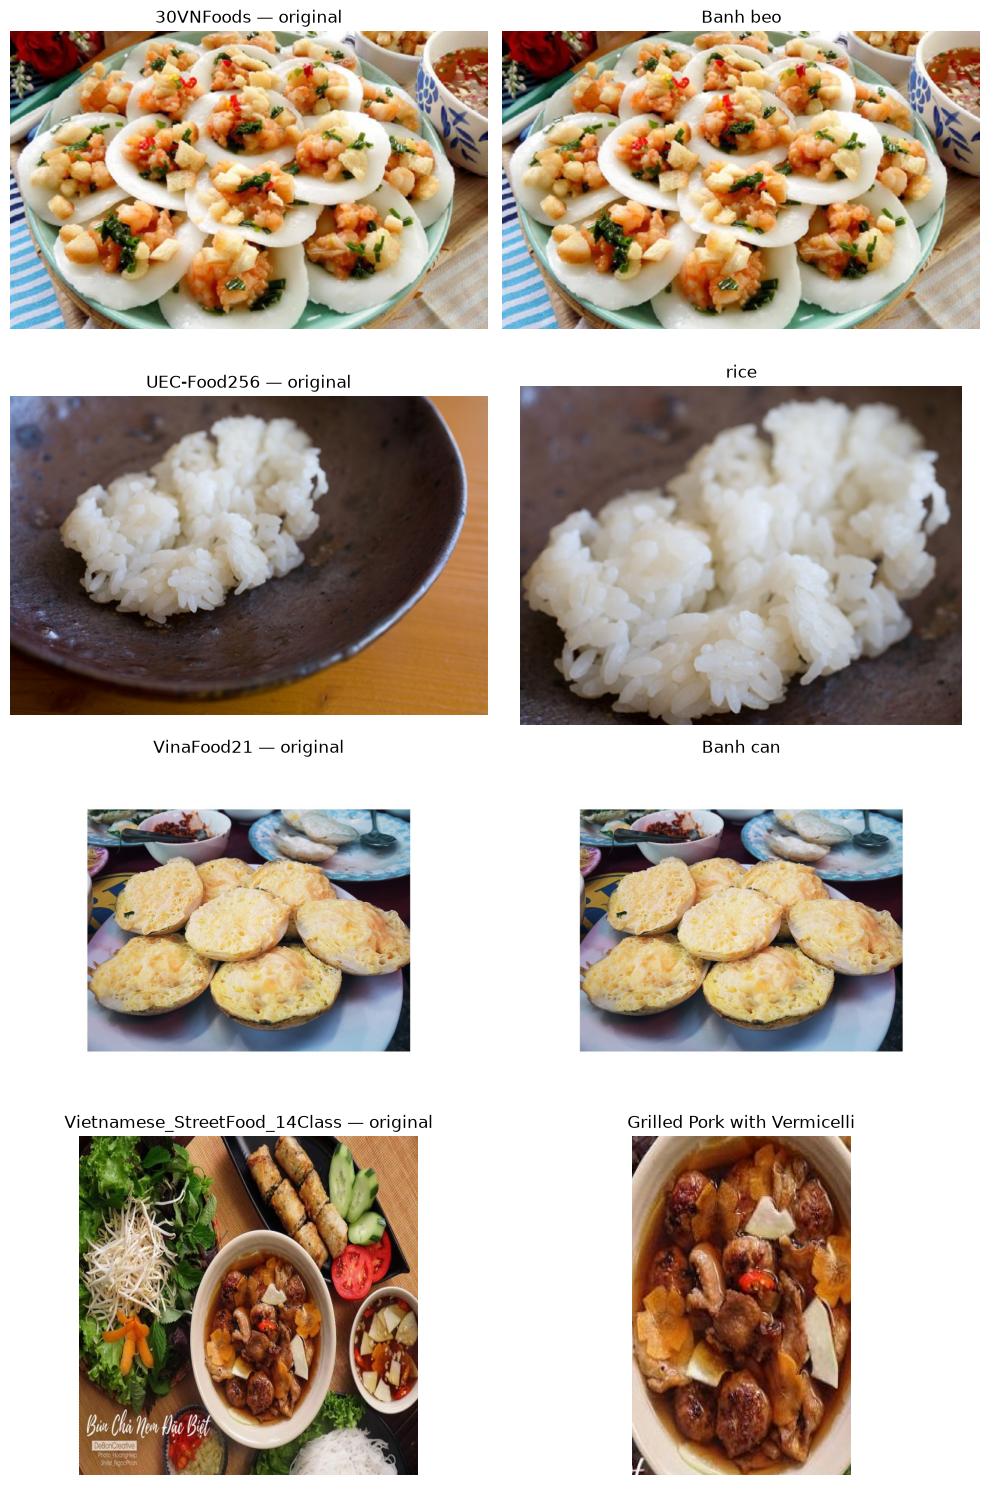

In [6]:
reader = ArchiveReader()
fig, axes = plt.subplots(4, 2, figsize=(10, 15))
for ax, source in zip(axes, mapping['sources']):
    row = next(r for ds in datasets.values() for r in ds.rows if r['source'] == source)
    ax[0].imshow(open_sample(dict(row, bbox=None), reader)); ax[0].set_title(source + ' — original')
    ax[1].imshow(open_sample(row, reader)); ax[1].set_title(mapping['classes'][row['canonical_id']]['source_name'])
    for a in ax: a.axis('off')
plt.tight_layout(); plt.show()


## 7. Augmentation preview
RandomResizedCrop(224, scale 0.8–1.0), horizontal flip, ImageNet normalization; no fixed seed.

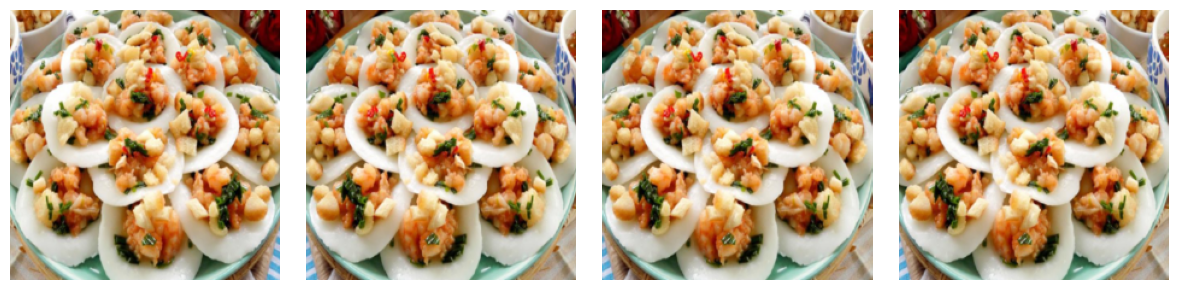

In [7]:
sample = open_sample(datasets['train'].rows[0], reader)
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax in axes:
    x = preprocess(True)(sample).permute(1, 2, 0).numpy()
    x = np.clip(x * np.array([.229, .224, .225]) + np.array([.485, .456, .406]), 0, 1)
    ax.imshow(x); ax.axis('off')
plt.tight_layout(); plt.show()


## 8. EfficientNet-B0 architecture and parameter count
Pretrained backbone, dynamic linear head; head warm-up followed by full fine-tuning.

In [8]:
model = build_model(CFG['architecture'], len(mapping['classes']), CFG['pretrained'])
print(model)
print('Total parameters:', sum(p.numel() for p in model.parameters()))
print('Head parameters:', sum(p.numel() for p in model.classifier.parameters()))


EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

## 9. Full training using the existing trainer
AdamW + CrossEntropy + cosine schedule, AMP on CUDA, clipping, TensorBoard, best/last checkpoints, RNG-restoring resume and validation Macro-F1 early stopping. Set RUN_FULL_TRAIN=True only when ready. All eligible train rows are loaded each epoch. Do not select epochs using test results.

In [9]:
RESUME = None  # e.g. RUN / 'last.pth'; keep the same config and output directory
if RUN_FULL_TRAIN:
    trainer.train(CFG, RUN, RESUME)
else:
    print('Full training has not been started. Train samples:', len(datasets['train']))
print('TensorBoard: python -m tensorboard.main --logdir runs/exp-001-unified4/tensorboard')


Full training has not been started. Train samples: 49536
TensorBoard: python -m tensorboard.main --logdir runs/exp-001-unified4/tensorboard


## 10. Train/validation loss, accuracy and Macro-F1

In [10]:
if (RUN / 'metrics.json').exists():
    history = json.loads((RUN / 'metrics.json').read_text())['history']
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, key in zip(axes, ['loss', 'top1_accuracy', 'macro_f1']):
        for split in ('train', 'val'):
            ax.plot([h['epoch'] for h in history], [h[split][key] for h in history], label=split)
        ax.set_title(key); ax.set_xlabel('Epoch'); ax.legend()
    plt.tight_layout(); plt.show()
else:
    print('No training history yet; no fabricated metrics.')


No training history yet; no fabricated metrics.


## 11. Confusion matrix
Validation matrix for the epoch selected by validation Macro-F1. Full-resolution values remain in metrics.json.

In [11]:
if (RUN / 'metrics.json').exists():
    best = max(history, key=lambda h: h['val']['macro_f1'])
    matrix = np.asarray(best['val']['confusion_matrix'])
    plt.figure(figsize=(10, 8)); plt.imshow(np.log1p(matrix), cmap='Blues'); plt.colorbar(label='log(1 + count)')
    plt.xlabel('Predicted canonical ID'); plt.ylabel('True canonical ID'); plt.title('Validation confusion matrix'); plt.show()
else:
    print('Available after training.')


Available after training.


## 12. Held-out test evaluation after training
Enable once the validation-selected best checkpoint is final. Evaluation uses every retained test sample; its output is not overwritten.

In [12]:
test_path = RUN / 'test_metrics.json'
if RUN_TEST_EVALUATION:
    assert (RUN / 'best.pth').exists(), 'Train first'
    trainer.evaluate(RUN / 'best.pth', 'test', test_path)
if test_path.exists():
    test_metrics = json.loads(test_path.read_text())
    display({k: test_metrics[k] for k in ['loss', 'top1_accuracy', 'top3_accuracy', 'macro_f1']})
    display(pd.DataFrame(test_metrics['per_class']))
else:
    print('Test has not been evaluated.')


Test has not been evaluated.


## 13. Example inference
Runs only with the trained checkpoint; uses a validation crop for illustration.

In [13]:
if (RUN / 'best.pth').exists():
    ck = torch.load(RUN / 'best.pth', map_location='cpu', weights_only=False)
    model.load_state_dict(ck['model']); model.eval()
    x, target = datasets['val'][0]
    with torch.inference_mode(): probabilities = model(x.unsqueeze(0)).softmax(1)[0]
    values, ids = probabilities.topk(5)
    display(pd.DataFrame({'class': [mapping['classes'][i]['source_name'] for i in ids.tolist()], 'probability': values.tolist()}))
    print('Target:', mapping['classes'][target]['source_name'])
else:
    print('Inference awaits a trained checkpoint.')


Inference awaits a trained checkpoint.


## 14. Conclusions
The experiment uses exactly four original sources and an auditable conservative taxonomy.
The manifest references original ZIP entries and creates crops at read time; only nested
ZIP containers are cached. Exclusions and duplicate edges are retained for inspection.
Near-duplicate checks are heuristic and cannot guarantee detection of all transformed copies.
Native capture/session metadata is unavailable, so group checks use UEC image IDs,
Roboflow filename identities and exact/near-image content. Review the taxonomy and per-source
validation coverage before interpreting cross-dataset metrics. Training and test performance
are intentionally absent until the corresponding cells are explicitly enabled.
